# **1. Data Loading**

### **(a) Load Data**

**Customers Data**

In [1]:
import pandas as pd

# Load the CSV files
customersDF = pd.read_csv('COFINFAD Colombian Fintech Financial Analytics Dat/customer_data.csv')
customersDF.head()


,customer_id,age,gender,location,income_bracket,occupation,education_level,marital_status,household_size,acquisition_channel,...,total_transaction_volume,transaction_frequency,last_transaction_date,preferred_transaction_type,first_transaction_date,weekend_transaction_ratio,avg_daily_transactions,customer_tenure,churn_probability,customer_lifetime_value
0,93716481,44,Male,"Pereira, Risaralda",Very High,Engineer,Master,Married,5,Partnership,...,60540250,0.030769,2023-12-05,Transfer,2023-01-05,0.300000,0.030769,11.633333,0.362269,3.124148e+08
1,49020929,44,Male,"Cali, Valle del Cauca",Medium,Construction Worker,Bachelor,Married,2,Paid Ad,...,23401550,0.032934,2023-12-18,Transfer,2023-02-05,0.181818,0.032934,11.500000,0.181790,1.670223e+08
2,52690950,45,Male,"Barranquilla, Atlántico",High,Construction Worker,Bachelor,Married,4,Paid Ad,...,35759150,0.050000,2023-10-27,Transfer,2023-01-31,0.300000,0.050000,8.766667,0.321265,1.940371e+07
3,23199751,45,Male,"Bogotá, Cundinamarca",High,Electrician,High School,Single,2,Referral,...,21186950,0.047782,2023-11-30,Transfer,2023-01-10,0.142857,0.047782,10.733333,0.336629,3.597811e+07
4,61997066,44,Female,"Bogotá, Cundinamarca",Medium,Cleaner,Bachelor,Married,3,Paid Ad,...,11640800,0.061889,2023-11-17,Payment,2023-01-05,0.315789,0.061889,11.633333,0.398151,3.046620e+08


**Transactions Data**

In [2]:
transactionsDF = pd.read_csv('COFINFAD Colombian Fintech Financial Analytics Dat/transactions_data.csv')
transactionsDF.head()


,customer_id,date,amount,type
0,93716481,2023-11-23,1262800,Transfer
1,93716481,2023-01-05,928900,Withdrawal
2,93716481,2023-11-05,1683100,Payment
3,93716481,2023-04-14,4507350,Payment
4,93716481,2023-08-04,2096150,Payment


### **(b) Check Datasets Shape**

In [3]:
# Check shapes
print("=" * 50)
print("DATASET SHAPES")
print("=" * 50)
print(f"Customers shape: {customersDF.shape}")
print(f"  - Rows: {customersDF.shape[0]:,}")
print(f"  - Columns: {customersDF.shape[1]}")

print(f"\nTransactions shape: {transactionsDF.shape}")
print(f"  - Rows: {transactionsDF.shape[0]:,}")
print(f"  - Columns: {transactionsDF.shape[1]}")

DATASET SHAPES
Customers shape: (48723, 54)
  - Rows: 48,723
  - Columns: 54

Transactions shape: (3159157, 4)
  - Rows: 3,159,157
  - Columns: 4


### **(c) Join Data**

In [4]:
# Perform the join (inner join - most common)
merged_dataDF = pd.merge(customersDF, transactionsDF, on='customer_id', how='inner')

print("\n" + "=" * 50)
print("JOINED DATASET")
print("=" * 50)
print(f"Merged data shape: {merged_dataDF.shape}")
print(f"  - Rows: {merged_dataDF.shape[0]:,}")
print(f"  - Columns: {merged_dataDF.shape[1]}")

# Check how many customers were lost/gained
unique_customers_original = customersDF['customer_id'].nunique()
unique_customers_merged = merged_dataDF['customer_id'].nunique()
unique_transactions_original = transactionsDF['customer_id'].nunique()

print("\n" + "=" * 50)
print("JOIN SUMMARY")
print("=" * 50)
print(f"Unique customers in original: {unique_customers_original:,}")
print(f"Unique customers in merged: {unique_customers_merged:,}")
print(f"Customers dropped (no transactions): {unique_customers_original - unique_customers_merged:,}")
print(f"Total transactions before join: {transactionsDF.shape[0]:,}")
print(f"Total rows after join: {merged_dataDF.shape[0]:,}")

# Quick preview
print("\n" + "=" * 50)
print("PREVIEW (first 5 rows)")
print("=" * 50)
merged_dataDF.head()




JOINED DATASET
Merged data shape: (3159157, 57)
  - Rows: 3,159,157
  - Columns: 57

JOIN SUMMARY
Unique customers in original: 48,723
Unique customers in merged: 48,723
Customers dropped (no transactions): 0
Total transactions before join: 3,159,157
Total rows after join: 3,159,157

PREVIEW (first 5 rows)


,customer_id,age,gender,location,income_bracket,occupation,education_level,marital_status,household_size,acquisition_channel,...,preferred_transaction_type,first_transaction_date,weekend_transaction_ratio,avg_daily_transactions,customer_tenure,churn_probability,customer_lifetime_value,date,amount,type
0,93716481,44,Male,"Pereira, Risaralda",Very High,Engineer,Master,Married,5,Partnership,...,Transfer,2023-01-05,0.3,0.030769,11.633333,0.362269,3.124148e+08,2023-11-23,1262800,Transfer
1,93716481,44,Male,"Pereira, Risaralda",Very High,Engineer,Master,Married,5,Partnership,...,Transfer,2023-01-05,0.3,0.030769,11.633333,0.362269,3.124148e+08,2023-01-05,928900,Withdrawal
2,93716481,44,Male,"Pereira, Risaralda",Very High,Engineer,Master,Married,5,Partnership,...,Transfer,2023-01-05,0.3,0.030769,11.633333,0.362269,3.124148e+08,2023-11-05,1683100,Payment
3,93716481,44,Male,"Pereira, Risaralda",Very High,Engineer,Master,Married,5,Partnership,...,Transfer,2023-01-05,0.3,0.030769,11.633333,0.362269,3.124148e+08,2023-04-14,4507350,Payment
4,93716481,44,Male,"Pereira, Risaralda",Very High,Engineer,Master,Married,5,Partnership,...,Transfer,2023-01-05,0.3,0.030769,11.633333,0.362269,3.124148e+08,2023-08-04,2096150,Payment


In [5]:
# Save data if you want
# merged_dataDF.to_csv('merged_data.csv', index=False)
# print("\nMerged data saved as 'merged_data.csv'")


# **2. Basic Data Understanding**

### **(a) Understanding Data Types & Checking Missing Data**

In [6]:
# View data types of all collumns using the info() method and verify if there are any missing values
merged_dataDF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3159157 entries, 0 to 3159156
Data columns (total 57 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   customer_id                 int64  
 1   age                         int64  
 2   gender                      object 
 3   location                    object 
 4   income_bracket              object 
 5   occupation                  object 
 6   education_level             object 
 7   marital_status              object 
 8   household_size              int64  
 9   acquisition_channel         object 
 10  customer_segment            object 
 11  savings_account             bool   
 12  credit_card                 bool   
 13  personal_loan               bool   
 14  investment_account          bool   
 15  insurance_product           bool   
 16  active_products             int64  
 17  app_logins_frequency        int64  
 18  feature_usage_diversity     int64  
 19  bill_payment_user    

In [7]:
print("Number of missing records:", merged_dataDF.isnull().sum())

Number of missing records: customer_id                         0
age                                 0
gender                              0
location                            0
income_bracket                      0
occupation                          0
education_level                     0
marital_status                      0
household_size                      0
acquisition_channel                 0
customer_segment                    0
savings_account                     0
credit_card                         0
personal_loan                       0
investment_account                  0
insurance_product                   0
active_products                     0
app_logins_frequency                0
feature_usage_diversity             0
bill_payment_user                   0
auto_savings_enabled                0
credit_utilization_ratio      1240943
international_transactions          0
failed_transactions                 0
tx_count                            0
avg_tx_value           

**Observations:**
- Missing values are present in three columns: credit_utilization_ratio, feature_requests, and complaint_topics.
- The data types include boolean columns for product ownership flags, integer columns for numerical counts and scores, float columns for ratios and probabilities, and object columns for categorical data, feature requests, complaint topics and dates.
- There are several potentially redundant columns that appear to measure similar concepts. For example, transaction count variables (tx_count, monthly_transaction_count, transaction_frequency, avg_daily_transactions), transaction value variables (avg_tx_value, average_transaction_value, total_tx_volume, total_transaction_volume), and transaction date variables (first_tx, last_tx, first_transaction_date, last_transaction_date, date) may contain overlapping information. These variables should be further examined using correlation analysis or business documentation before determining whether any can be removed to reduce redundancy and improve model interpretability.


**Recommendations based on Observations:**
- Address the missing values in the 3 columns by either dropping them or imputing the missing data
- Convert object columns like dates to proper datetime format for better analysis.
- Investigate and remove redundant transaction columns if they contain duplicate information to reduce memory usage.

### **(b) Checking for Duplicates**

In [8]:
num_of_duplicates = merged_dataDF.duplicated().sum()
print('Number of Duplicates Discovered:', num_of_duplicates)

Number of Duplicates Discovered: 102


102 duplicate records were identified. These should be investigated to determine whether they are true duplicate records or legitimate repeated transactions before removal.

## **3. Exploratory Data Analysis (EDA)**

**Descriptive Statistics**

In [9]:
merged_dataDF.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,3159157.0,5.458967e+07,2.641356e+07,1.000062e+07,3.212021e+07,5.492876e+07,7.794008e+07,9.999980e+07
age,3159157.0,4.508741e+01,1.200964e+01,2.900000e+01,3.000000e+01,4.500000e+01,5.900000e+01,6.000000e+01
household_size,3159157.0,3.557036e+00,1.576330e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00,1.300000e+01
active_products,3159157.0,2.062488e+00,1.200450e+00,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00
app_logins_frequency,3159157.0,2.218168e+01,1.172220e+01,4.000000e+00,1.500000e+01,2.200000e+01,3.000000e+01,1.000000e+02
feature_usage_diversity,3159157.0,2.221534e+00,1.698522e+00,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,1.000000e+01
credit_utilization_ratio,1918214.0,2.824389e-01,1.563466e-01,1.794056e-04,1.593920e-01,2.685029e-01,3.804243e-01,9.375464e-01
international_transactions,3159157.0,4.880318e-01,7.033100e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,6.000000e+00
failed_transactions,3159157.0,1.840333e-01,4.285558e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
tx_count,3159157.0,5.839991e+03,1.382561e+04,1.000000e+01,5.100000e+01,3.470000e+02,3.593000e+03,7.746500e+04


Note: Using the describe() function mainly shows descriptive statisitcs of numerical or float collumns. Any text collumns will not be featured

The records are currently in scientific notation format so that needs to be changed accordingly.



In [10]:
# Display numbers without scientific notation in 2 decimal places
pd.set_option('display.float_format', '{:,.2f}'.format)

# Now describe() will show full numbers without scientific notation
merged_dataDF.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,"3,159,157.00","54,589,667.41","26,413,559.41","10,000,617.00","32,120,213.00","54,928,756.00","77,940,083.00","99,999,798.00"
age,"3,159,157.00",45.09,12.01,29.00,30.00,45.00,59.00,60.00
household_size,"3,159,157.00",3.56,1.58,1.00,2.00,3.00,5.00,13.00
active_products,"3,159,157.00",2.06,1.20,1.00,1.00,2.00,3.00,5.00
app_logins_frequency,"3,159,157.00",22.18,11.72,4.00,15.00,22.00,30.00,100.00
feature_usage_diversity,"3,159,157.00",2.22,1.70,0.00,1.00,2.00,3.00,10.00
credit_utilization_ratio,"1,918,214.00",0.28,0.16,0.00,0.16,0.27,0.38,0.94
international_transactions,"3,159,157.00",0.49,0.70,0.00,0.00,0.00,1.00,6.00
failed_transactions,"3,159,157.00",0.18,0.43,0.00,0.00,0.00,0.00,4.00
tx_count,"3,159,157.00","5,839.99","13,825.61",10.00,51.00,347.00,"3,593.00","77,465.00"


**Observations:**

1. Data Distribution Patterns:
    - Transaction-related metrics (tx_count, avg_tx_value, total_tx_volume, customer_lifetime_value) are highly right-skewed - the mean values significantly exceed the medians, indicating that a small number of high-value customers are driving the averages upward
    - Household size exhibits a relatively reasonable distribution, whereas age appears artificially generated and does not resemble a natural continuous demographic distribution.
    - Engagement metrics (app_logins_frequency, feature_usage_diversity) show moderate variation across the customer base.
2. Customer Value & Risk:
    - NPS scores are mostly negatives highlighting critical loyalty issues as there are a huge number of detractors than promoters given than detractors is categorized based on NPS score of less than 6.
    - Average churn probability is 33% with customers ranging from 11-50% risk
    - Customer Lifetime Value is extremely skewed where a small VIP segment drives disproportionate value as seen from the mean value of 1.55 billion in comparison to the median value of 0.42 billion.
3. Positive Indicators:
    - Overall satisfaction is high (4.26/6) with good app rating (4.16/5).
    - Failed transactions are low - 75% of customers have zero failures
    - Healthy credit utilization at 28% average

**Import Libraries**

In [11]:
# Required libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [12]:
# ============================================
# CORRELATION MATRIX - ALL NUMERIC COLUMNS
# ============================================
print("\n" + "=" * 60)
print("CORRELATION MATRIX - ALL NUMERIC COLUMNS")
print("=" * 60)

# Select only numeric columns
numeric_cols = merged_dataDF.select_dtypes(include=['int64', 'float64']).columns
print(f"\nTotal numeric columns: {len(numeric_cols)}")

# Calculate correlation matrix
corr_matrix = merged_dataDF[numeric_cols].corr()

# Display correlation matrix as a table
print("\n📊 Correlation Matrix:")
display(corr_matrix)




CORRELATION MATRIX - ALL NUMERIC COLUMNS

Total numeric columns: 30

📊 Correlation Matrix:


,customer_id,age,household_size,active_products,app_logins_frequency,feature_usage_diversity,credit_utilization_ratio,international_transactions,failed_transactions,tx_count,...,monthly_transaction_count,average_transaction_value,total_transaction_volume,transaction_frequency,weekend_transaction_ratio,avg_daily_transactions,customer_tenure,churn_probability,customer_lifetime_value,amount
customer_id,1.00,-0.09,0.04,-0.05,-0.01,0.00,-0.04,0.04,0.04,0.10,...,-0.01,0.03,0.00,-0.01,-0.04,-0.01,0.08,0.02,0.01,0.06
age,-0.09,1.00,0.01,0.03,-0.05,0.24,0.01,-0.02,0.01,0.10,...,-0.00,-0.04,-0.00,-0.00,0.05,-0.00,-0.03,0.14,-0.05,0.00
household_size,0.04,0.01,1.00,0.04,0.02,0.04,-0.02,-0.01,0.02,-0.01,...,0.01,0.01,0.00,0.01,-0.02,0.01,0.06,-0.05,0.02,0.03
active_products,-0.05,0.03,0.04,1.00,-0.03,0.06,-0.01,0.03,-0.01,-0.16,...,-0.00,0.02,-0.00,-0.00,0.01,-0.00,-0.08,-0.79,0.05,-0.07
app_logins_frequency,-0.01,-0.05,0.02,-0.03,1.00,-0.02,0.03,0.06,-0.01,-0.09,...,-0.00,0.01,-0.00,-0.00,-0.07,-0.00,0.05,-0.23,0.01,0.03
feature_usage_diversity,0.00,0.24,0.04,0.06,-0.02,1.00,0.02,0.00,0.04,-0.18,...,0.01,0.02,0.00,0.01,0.04,0.01,0.05,0.06,0.06,-0.05
credit_utilization_ratio,-0.04,0.01,-0.02,-0.01,0.03,0.02,1.00,0.01,-0.02,-0.08,...,0.02,0.01,0.01,0.02,-0.05,0.02,0.04,0.03,0.04,0.02
international_transactions,0.04,-0.02,-0.01,0.03,0.06,0.00,0.01,1.00,-0.04,-0.10,...,-0.00,0.02,0.00,-0.00,-0.03,-0.00,0.06,0.00,0.02,-0.01
failed_transactions,0.04,0.01,0.02,-0.01,-0.01,0.04,-0.02,-0.04,1.00,-0.07,...,0.00,-0.01,0.00,0.00,-0.02,0.00,0.02,0.03,0.02,-0.00
tx_count,0.10,0.10,-0.01,-0.16,-0.09,-0.18,-0.08,-0.10,-0.07,1.00,...,-0.03,-0.11,-0.01,-0.03,0.03,-0.03,-0.13,-0.20,-0.18,0.26


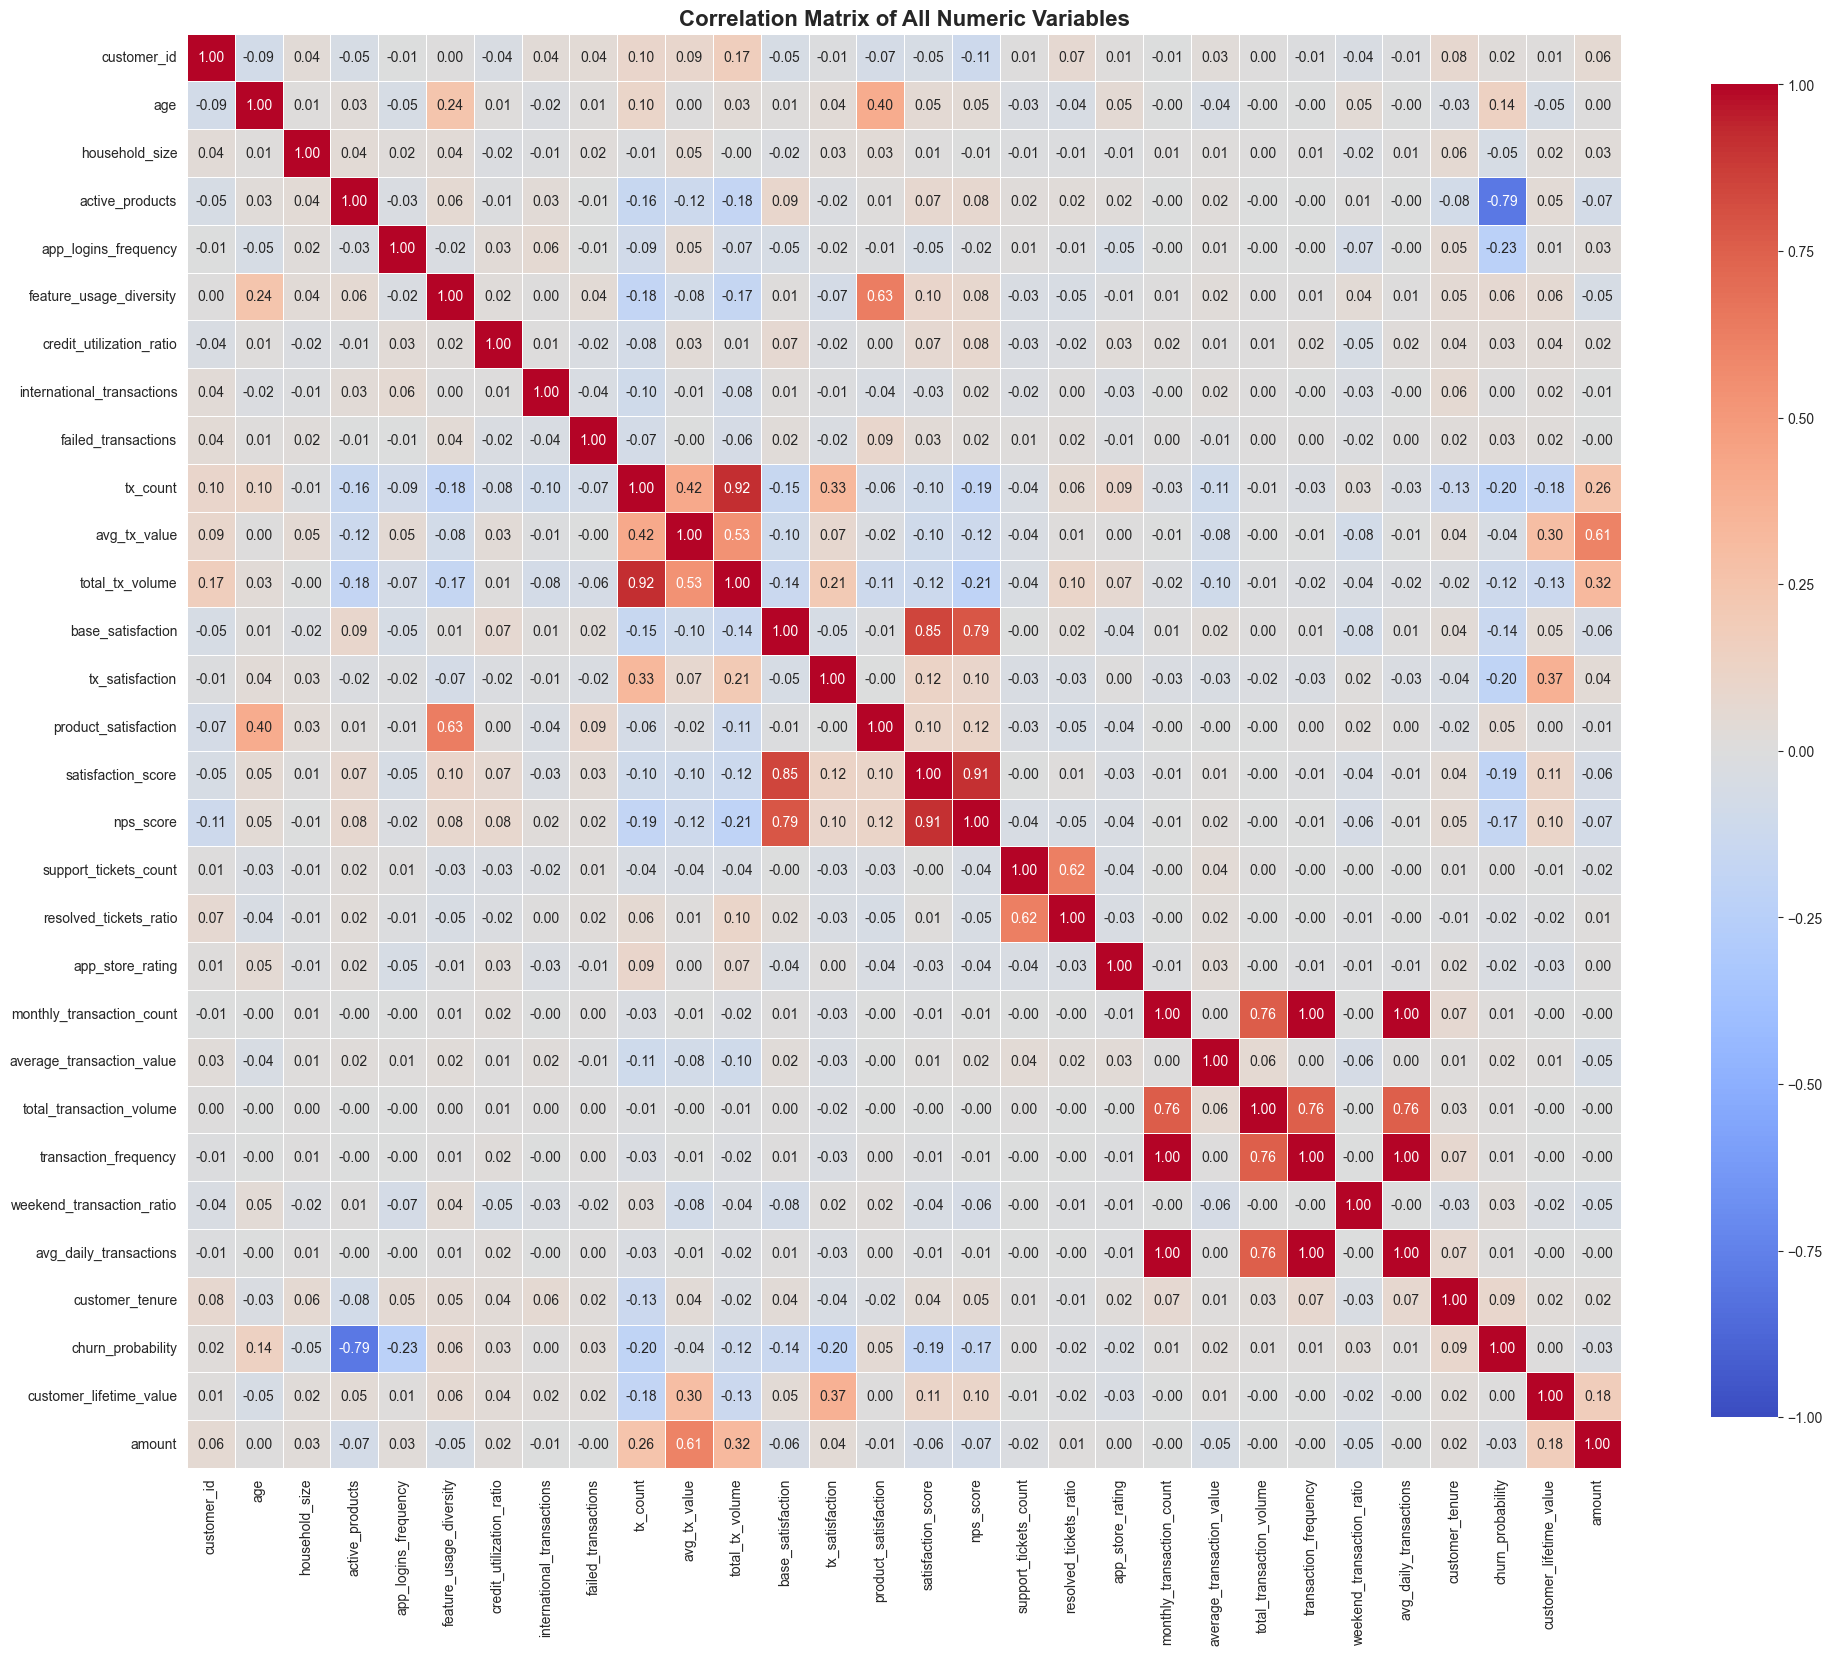

In [13]:
# ============================================
# VISUALIZE CORRELATION MATRIX - HEATMAP
# ============================================

# Set up the matplotlib figure
plt.figure(figsize=(20, 18))

# Create heatmap
sns.heatmap(corr_matrix, 
            annot=True,           # Show values in cells
            fmt='.2f',            # Format to 2 decimal places
            cmap='coolwarm',      # Color scheme
            center=0,             # Center at 0
            square=True,          # Square cells
            linewidths=0.5,       # Grid lines
            cbar_kws={'shrink': 0.8},
            vmin=-1, vmax=1)      # Full correlation range

plt.title('Correlation Matrix of All Numeric Variables', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### Correlation Matrix – Summarized Insights

- The majority of numerical features exhibit weak linear correlations, with most correlation coefficients falling between −0.20 and 0.20. This suggests that most variables capture different aspects of customer behaviour and are unlikely to cause severe multicollinearity.
- Several transaction activity variables are highly correlated. In particular, monthly_transaction_count, transaction_frequency, and avg_daily_transactions are almost perfectly correlated (r ≈ 1.00), indicating that these variables contain highly similar information and may be redundant.
- Similarly, tx_count and total_tx_volume show a strong positive correlation (r ≈ 0.92), indicating that customers who perform more transactions generally generate higher overall transaction volumes.
- Strong positive relationships are also observed between base_satisfaction and satisfaction_score (r ≈ 0.85), and between satisfaction_score and nps_score (r ≈ 0.91), suggesting that higher overall customer satisfaction is closely associated with greater customer loyalty.

**Key Correlation Themes**
1. Customer Satisfaction is Closely Associated with Loyalty
Base satisfaction has a strong positive correlation with overall satisfaction (r ≈ 0.85).
Overall satisfaction is also strongly positively correlated with NPS score (r ≈ 0.91).
Churn probability shows a weak negative correlation with satisfaction_score, suggesting that customers with higher satisfaction tend to have slightly lower churn risk.
2. Transaction Activity Reflects Overall Transaction Volume
tx_count has a strong positive correlation with total_tx_volume (r ≈ 0.92).
Customers with higher transaction counts generally contribute larger total transaction volumes.
These variables capture related aspects of customer transaction behaviour and should be considered during feature selection.
3. Redundant Transaction Frequency Variables
monthly_transaction_count, transaction_frequency, and avg_daily_transactions are almost perfectly correlated (r ≈ 1.00).
Since these variables measure nearly identical information, retaining all of them may introduce multicollinearity without improving model performance.
Selecting one representative variable from this group can simplify the predictive model.
4. Most Customer Characteristics Show Weak Individual Correlations
Variables such as age, household_size, app_logins_frequency, credit_utilization_ratio, international_transactions, and failed_transactions generally exhibit weak pairwise correlations with most other variables.
Although these features are weak predictors individually, they may still contribute useful information when combined with other variables in machine learning models.

**Recommendations**
1. Reduce Feature Redundancy
Remove or combine highly correlated transaction frequency variables before model development.
This can reduce multicollinearity, improve model interpretability, and simplify feature selection.
2. Prioritise Satisfaction-Related Variables
Since base_satisfaction, satisfaction_score, and nps_score are strongly related, these variables provide valuable insights into customer experience and loyalty.
Consider selecting representative variables to avoid redundant information during modelling.
3. Retain Transaction Activity Metrics
Transaction count and transaction volume are strongly associated with overall customer activity.
These variables are likely to provide useful predictive information for customer behaviour and future demand analysis.
4. Combine Multiple Feature Categories
As most individual variables exhibit weak correlations, predictive performance is likely to benefit from combining customer demographics, engagement metrics, financial behaviour, and transaction history rather than relying on any single feature


CATEGORY 1: DEMOGRAPHICS DISTRIBUTION


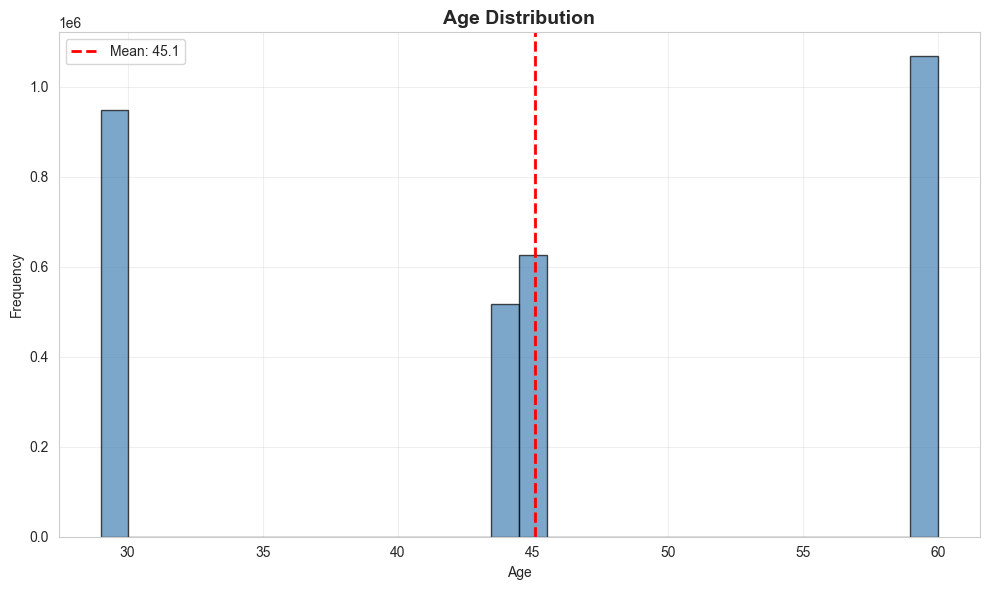

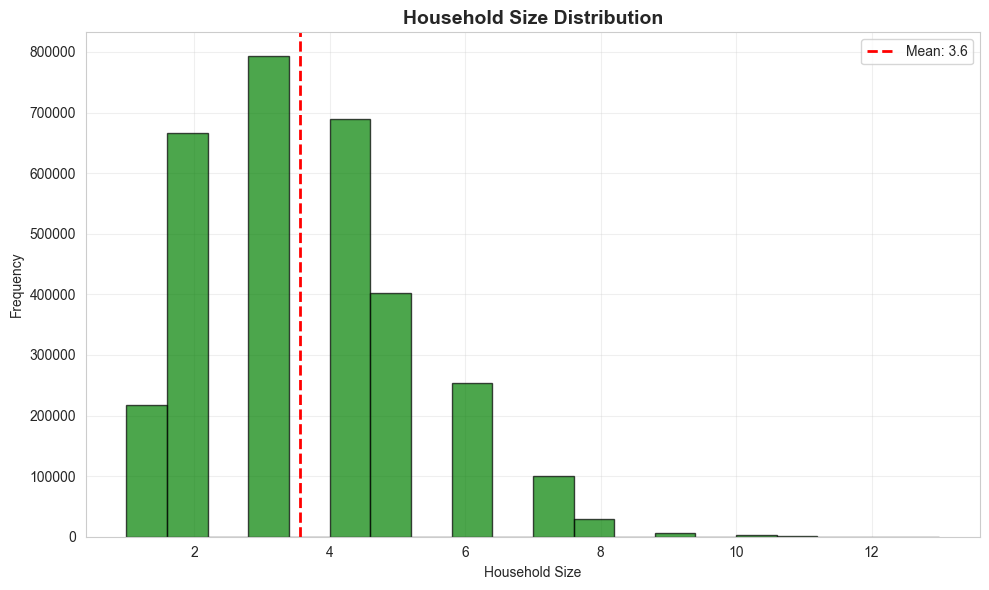

In [14]:
# ============================================
# CATEGORY 1: DEMOGRAPHICS DISTRIBUTION
# ============================================
print("\n" + "=" * 60)
print("CATEGORY 1: DEMOGRAPHICS DISTRIBUTION")
print("=" * 60)

# Age Distribution
plt.figure(figsize=(10, 6))
merged_dataDF['age'].hist(bins=30, edgecolor='black', alpha=0.7, color='steelblue')
plt.axvline(merged_dataDF['age'].mean(), color='red', linestyle='--', linewidth=2, 
            label=f"Mean: {merged_dataDF['age'].mean():.1f}")
plt.title('Age Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Household Size Distribution
plt.figure(figsize=(10, 6))
merged_dataDF['household_size'].hist(bins=20, edgecolor='black', alpha=0.7, color='green')
plt.axvline(merged_dataDF['household_size'].mean(), color='red', linestyle='--', linewidth=2,
            label=f"Mean: {merged_dataDF['household_size'].mean():.1f}")
plt.title('Household Size Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Household Size')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:
# Check age distribution more closely
print("=" * 60)
print("AGE DISTRIBUTION ANALYSIS")
print("=" * 60)

# Check unique age values
unique_ages = merged_dataDF['age'].unique()
print(f"Unique age values: {sorted(unique_ages)}")
print(f"Number of unique ages: {len(unique_ages)}")

# Check if all ages between 29-60 exist
expected_ages = set(range(29, 61))
missing_ages = expected_ages - set(unique_ages)
if missing_ages:
    print(f"⚠️ Missing ages: {sorted(missing_ages)}")
else:
    print("✅ All ages 29-60 are present")

# Check age distribution
age_counts = merged_dataDF['age'].value_counts().sort_index()
print("\nAge Distribution (Counts):")
print(age_counts.head(10))
print("...")
print(age_counts.tail(10))



AGE DISTRIBUTION ANALYSIS
Unique age values: [np.int64(29), np.int64(30), np.int64(44), np.int64(45), np.int64(59), np.int64(60)]
Number of unique ages: 6
⚠️ Missing ages: [31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58]

Age Distribution (Counts):
age
29    514245
30    433583
44    517177
45    626197
59    494354
60    573601
Name: count, dtype: int64
...
age
29    514245
30    433583
44    517177
45    626197
59    494354
60    573601
Name: count, dtype: int64


**CATEGORY 1: DEMOGRAPHICS DISTRIBUTION Observations:**
- Age Distribution: Customers range from 29 to 60 years old with an average age of 45 years. However, the age column contains only 6 unique values (29, 30, 44, 45, 59, 60) with 26 missing age values between 31-43 and 46-58. The clean cutoffs at 29 and 60, combined with ages clustered into 3 distinct pairs, strongly suggests that the dataset may have been synthetically generated or discretized during preprocessing.
- Household Size Distribution: Most customers (75%) have 2-5 people in their household with an average of 3.6 people. The distribution appears reasonable and natural with some outliers extending up to 13 people, which may represent multi-generational or extended family households. The median household size is 3.0, indicating typical family structures.
- Data Quality Concern: The age column shows clear signs of synthetic generation with only 6 unique values and clean truncation at both ends. Age-based analysis should be interpreted with caution and age should be treated as a categorical variable (Young Adult: 29-30, Middle-Aged: 44-45, Senior Citizen: 59-60) rather than continuous for any meaningful analysis.


CATEGORY 2: FINANCIAL PRODUCT OWNERSHIP


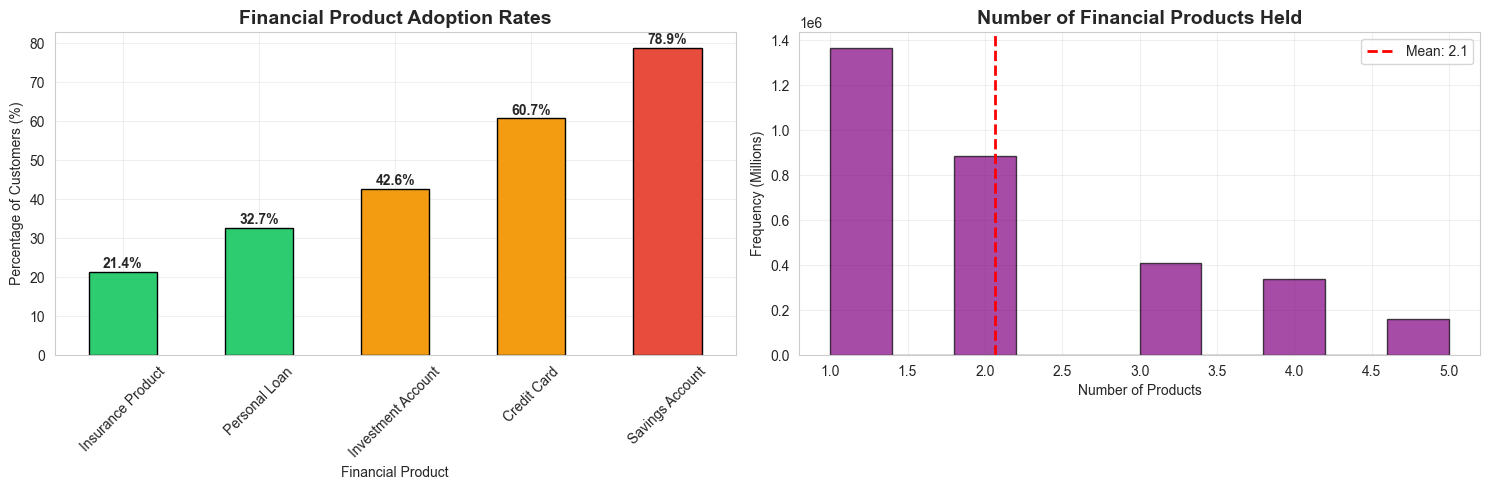

In [16]:
# ============================================
# CATEGORY 2: FINANCIAL PRODUCT OWNERSHIP
# ============================================
print("\n" + "=" * 60)
print("CATEGORY 2: FINANCIAL PRODUCT OWNERSHIP")
print("=" * 60)

# Define financial product columns (boolean columns)
financial_product_cols = ['savings_account', 'credit_card', 'personal_loan', 
                'investment_account', 'insurance_product']

# Filter to only columns that exist in the dataset
financial_product_cols = [col for col in financial_product_cols if col in merged_dataDF.columns]

# ---------------------------------------------------------------------
# HOW TRUE/FALSE ARE CONVERTED TO 1/0:
# 
# When pandas calculates .mean() on boolean columns:
#   - TRUE  is treated as 1
#   - FALSE is treated as 0
#
# Example for savings_account column (5 customers):
#   Values: [TRUE, TRUE, TRUE, TRUE, TRUE]
#   Converted to: [1, 1, 1, 1, 1]
#   Sum = 5
#   Mean = 5 / 5 = 1.0
#   Percentage = 1.0 * 100 = 100%
#
# Example for personal_loan column (5 customers):
#   Values: [FALSE, FALSE, FALSE, FALSE, FALSE]
#   Converted to: [0, 0, 0, 0, 0]
#   Sum = 0
#   Mean = 0 / 5 = 0.0
#   Percentage = 0.0 * 100 = 0%
# ---------------------------------------------------------------------

# Calculate adoption rates
# Step 1: merged_dataDF[financial_product_cols] - Select only boolean columns
# Step 2: .mean() - Converts TRUE=1, FALSE=0, then calculates average
# Step 3: * 100 - Converts decimal to percentage
product_ownership = merged_dataDF[financial_product_cols].mean() * 100

# Map to readable names for chart labels
product_names = {
    'savings_account': 'Savings Account',
    'credit_card': 'Credit Card',
    'personal_loan': 'Personal Loan',
    'investment_account': 'Investment Account',
    'insurance_product': 'Insurance Product'
}
product_ownership.index = [product_names[col] for col in product_ownership.index]

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ----- Chart 1: Product Adoption Bar Chart -----
# Color coding: Green = High (>50%), Orange = Medium (30-50%), Red = Low (<30%)
colors = ['#2ecc71' if pct > 50 else '#e74c3c' if pct < 30 else '#f39c12' for pct in product_ownership]
product_ownership.sort_values().plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Financial Product Adoption Rates', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Financial Product')
axes[0].set_ylabel('Percentage of Customers (%)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

# Add value labels on top of bars
for i, v in enumerate(product_ownership.sort_values()):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=10, fontweight='bold')

# ----- Chart 2: Active Products Distribution -----
# Shows how many products each customer owns (calculated from the boolean columns)
merged_dataDF['active_products'].hist(bins=10, ax=axes[1], edgecolor='black', alpha=0.7, color='purple')
axes[1].axvline(merged_dataDF['active_products'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['active_products'].mean():.1f}")
axes[1].set_title('Number of Financial Products Held', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Products')
axes[1].set_ylabel('Frequency (Millions)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**CATEGORY 2: FINANCIAL PRODUCT OWNERSHIP Observations:**
- Product Adoption Rates: Product adoption varies significantly across financial products. Savings accounts show the highest adoption, while insurance products show the lowest. This pattern is typical for banking institutions where basic products like savings accounts are more commonly held than specialized products like insurance.
- Average Products Held: Customers hold an average of 2.06 products with a range of 1 to 5 products. Notably, no customers have 0 products (minimum is 1), suggesting the dataset may only include active customers with at least one financial product. This indicates potential selection bias in the data.
- Cross-Selling Opportunity: The variation in product adoption rates suggests significant cross-selling potential. Customers who hold basic products (savings accounts, credit cards) could be targeted for additional products like investment accounts or insurance to increase their product portfolio and customer lifetime value.



CATEGORY 3: DIGITAL ENGAGEMENT


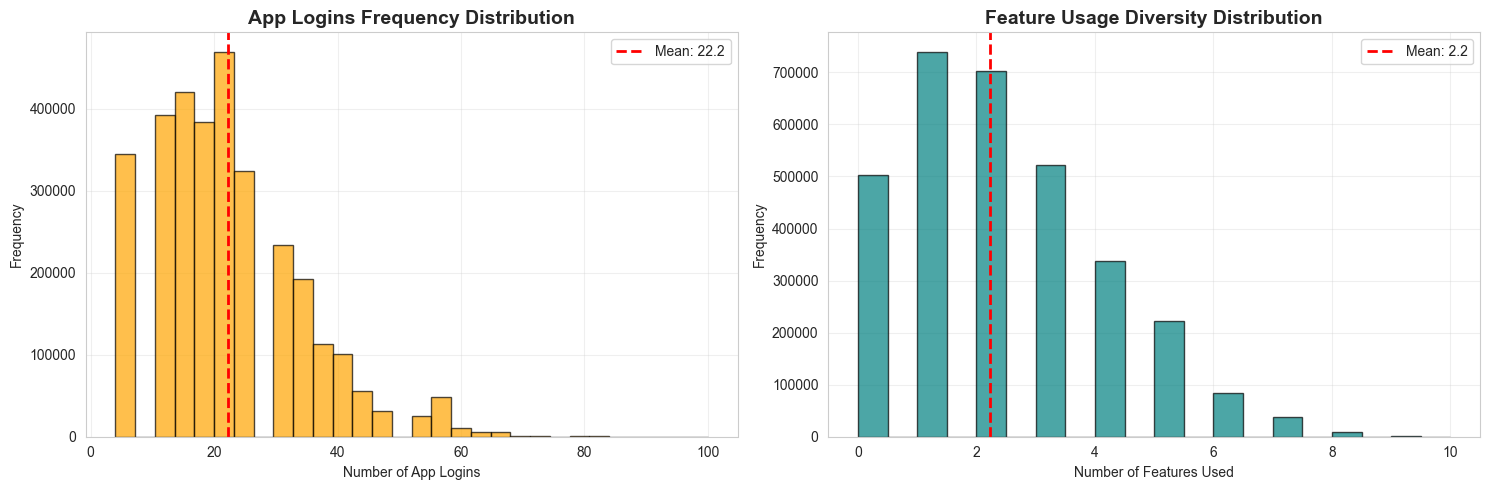

In [17]:
# ============================================
# CATEGORY 3: DIGITAL ENGAGEMENT
# ============================================
print("\n" + "=" * 60)
print("CATEGORY 3: DIGITAL ENGAGEMENT")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# App Logins Distribution
merged_dataDF['app_logins_frequency'].hist(bins=30, ax=axes[0], edgecolor='black', alpha=0.7, color='orange')
axes[0].axvline(merged_dataDF['app_logins_frequency'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['app_logins_frequency'].mean():.1f}")
axes[0].set_title('App Logins Frequency Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of App Logins')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Feature Usage Diversity
merged_dataDF['feature_usage_diversity'].hist(bins=20, ax=axes[1], edgecolor='black', alpha=0.7, color='teal')
axes[1].axvline(merged_dataDF['feature_usage_diversity'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['feature_usage_diversity'].mean():.1f}")
axes[1].set_title('Feature Usage Diversity Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Features Used')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



**CATEGORY 3: DIGITAL ENGAGEMENT Observations**:
- App Login Frequency: Customers log into the mobile app an average of 22 times with a range of 4 to 100 logins. This indicates moderate to good digital engagement across the customer base. The wide variation suggests different levels of digital adoption among customers.
- Feature Usage Diversity: Customers use an average of 2.2 features with 50% of customers using only 1-2 features. While some power users utilize up to 10 features, they are rare. This pattern reveals a significant engagement opportunity where a large portion of customers are underutilizing available app features.
- Engagement Opportunity: The low feature usage diversity presents a clear upsell opportunity. Customers using fewer features could be targeted with educational content and feature promotion to increase their engagement, which may positively impact satisfaction and reduce churn risk.



CATEGORY 4: FINANCIAL BEHAVIOR


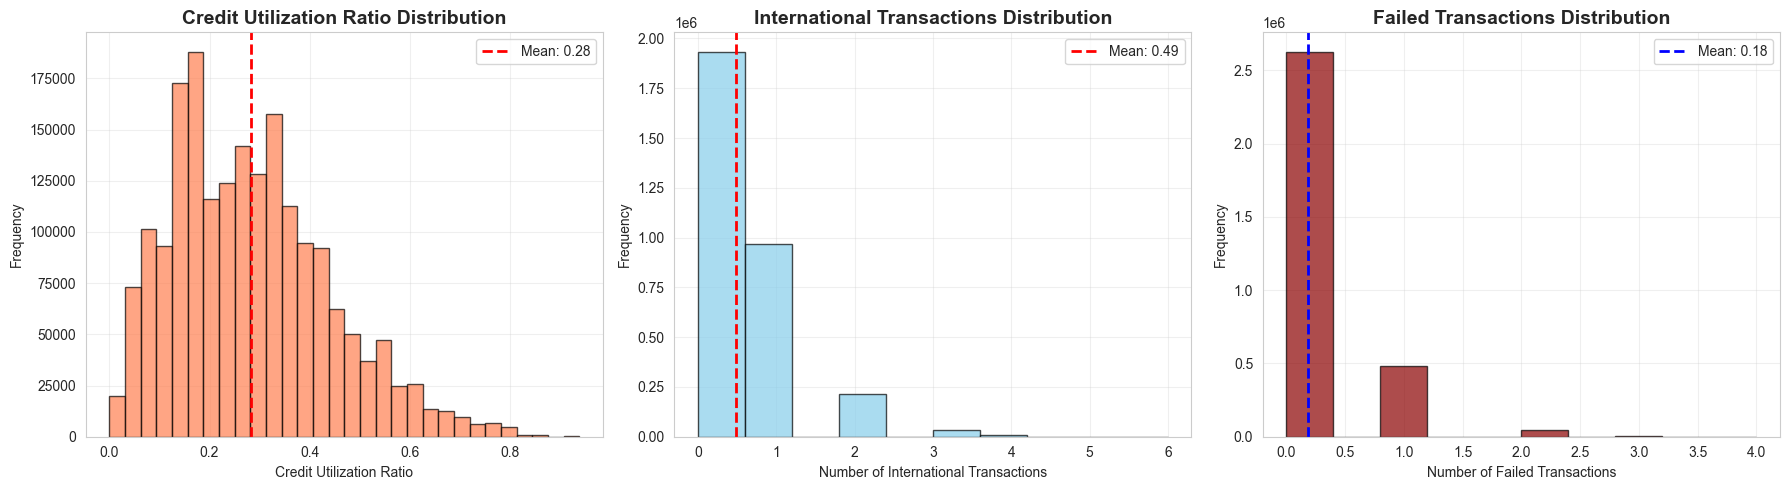

In [18]:
# ============================================
# CATEGORY 4: FINANCIAL BEHAVIOR
# ============================================
print("\n" + "=" * 60)
print("CATEGORY 4: FINANCIAL BEHAVIOR")
print("=" * 60)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Credit Utilization Ratio
merged_dataDF['credit_utilization_ratio'].hist(bins=30, ax=axes[0], edgecolor='black', alpha=0.7, color='coral')
axes[0].axvline(merged_dataDF['credit_utilization_ratio'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['credit_utilization_ratio'].mean():.2f}")
axes[0].set_title('Credit Utilization Ratio Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Credit Utilization Ratio')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# International Transactions
merged_dataDF['international_transactions'].hist(bins=10, ax=axes[1], edgecolor='black', alpha=0.7, color='skyblue')
axes[1].axvline(merged_dataDF['international_transactions'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['international_transactions'].mean():.2f}")
axes[1].set_title('International Transactions Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of International Transactions')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Failed Transactions
merged_dataDF['failed_transactions'].hist(bins=10, ax=axes[2], edgecolor='black', alpha=0.7, color='darkred')
axes[2].axvline(merged_dataDF['failed_transactions'].mean(), color='blue', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['failed_transactions'].mean():.2f}")
axes[2].set_title('Failed Transactions Distribution', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Number of Failed Transactions')
axes[2].set_ylabel('Frequency')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



**CATEGORY 4: FINANCIAL BEHAVIOR Observations:**
- Credit Utilization: The average credit utilization ratio is 28% with a range of 0% to 94%, indicating generally healthy credit management among customers. However, this data is only available for approximately 1.9 million customers (61% of the dataset), with 39% missing values likely representing customers without credit cards.
- International Transactions: Half of all customers (50%) have zero international transactions, with the maximum being 6. This suggests limited global financial activity, which may be characteristic of a domestic-focused customer base or a market with limited international banking needs.
- Failed Transactions: The vast majority of customers (75%) have zero failed transactions with an average of only 0.18 failures per customer. This indicates good operational health and reliable transaction processing systems, contributing positively to customer experience.


CATEGORY 5: TRANSACTION METRICS


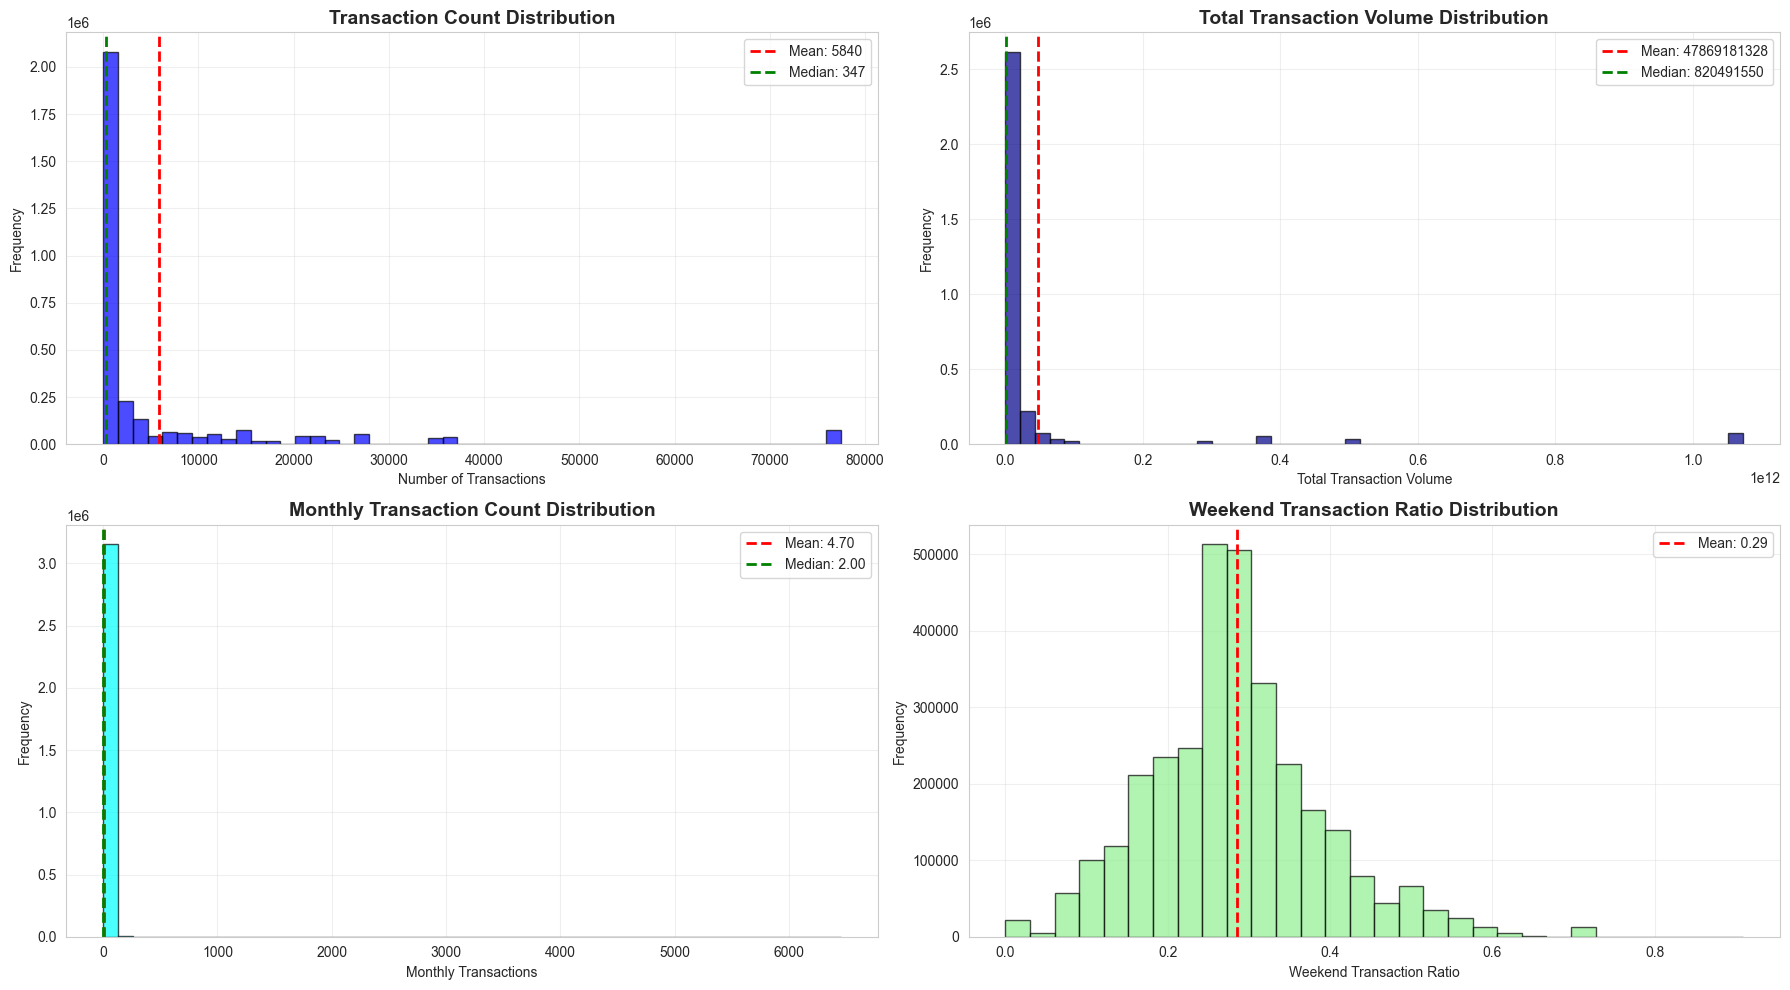

In [19]:
# ============================================
# CATEGORY 5: TRANSACTION METRICS
# ============================================
print("\n" + "=" * 60)
print("CATEGORY 5: TRANSACTION METRICS")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(18, 10))

# Transaction Count
merged_dataDF['tx_count'].hist(bins=50, ax=axes[0,0], edgecolor='black', alpha=0.7, color='blue')
axes[0,0].axvline(merged_dataDF['tx_count'].mean(), color='red', linestyle='--', linewidth=2,
                  label=f"Mean: {merged_dataDF['tx_count'].mean():.0f}")
axes[0,0].axvline(merged_dataDF['tx_count'].median(), color='green', linestyle='--', linewidth=2,
                  label=f"Median: {merged_dataDF['tx_count'].median():.0f}")
axes[0,0].set_title('Transaction Count Distribution', fontsize=14, fontweight='bold')
axes[0,0].set_xlabel('Number of Transactions')
axes[0,0].set_ylabel('Frequency')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Total Transaction Volume
merged_dataDF['total_tx_volume'].hist(bins=50, ax=axes[0,1], edgecolor='black', alpha=0.7, color='darkblue')
axes[0,1].axvline(merged_dataDF['total_tx_volume'].mean(), color='red', linestyle='--', linewidth=2,
                  label=f"Mean: {merged_dataDF['total_tx_volume'].mean():.0f}")
axes[0,1].axvline(merged_dataDF['total_tx_volume'].median(), color='green', linestyle='--', linewidth=2,
                  label=f"Median: {merged_dataDF['total_tx_volume'].median():.0f}")
axes[0,1].set_title('Total Transaction Volume Distribution', fontsize=14, fontweight='bold')
axes[0,1].set_xlabel('Total Transaction Volume')
axes[0,1].set_ylabel('Frequency')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Monthly Transaction Count
merged_dataDF['monthly_transaction_count'].hist(bins=50, ax=axes[1,0], edgecolor='black', alpha=0.7, color='cyan')
axes[1,0].axvline(merged_dataDF['monthly_transaction_count'].mean(), color='red', linestyle='--', linewidth=2,
                  label=f"Mean: {merged_dataDF['monthly_transaction_count'].mean():.2f}")
axes[1,0].axvline(merged_dataDF['monthly_transaction_count'].median(), color='green', linestyle='--', linewidth=2,
                  label=f"Median: {merged_dataDF['monthly_transaction_count'].median():.2f}")
axes[1,0].set_title('Monthly Transaction Count Distribution', fontsize=14, fontweight='bold')
axes[1,0].set_xlabel('Monthly Transactions')
axes[1,0].set_ylabel('Frequency')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# Weekend Transaction Ratio
merged_dataDF['weekend_transaction_ratio'].hist(bins=30, ax=axes[1,1], edgecolor='black', alpha=0.7, color='lightgreen')
axes[1,1].axvline(merged_dataDF['weekend_transaction_ratio'].mean(), color='red', linestyle='--', linewidth=2,
                  label=f"Mean: {merged_dataDF['weekend_transaction_ratio'].mean():.2f}")
axes[1,1].set_title('Weekend Transaction Ratio Distribution', fontsize=14, fontweight='bold')
axes[1,1].set_xlabel('Weekend Transaction Ratio')
axes[1,1].set_ylabel('Frequency')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



**CATEGORY 5: TRANSACTION METRICS Observations:**
Transaction Count: The transaction count is highly right-skewed with a mean of 5,840 transactions compared to a median of only 347, meaning the mean is 17 times higher than the median. This indicates that a small number of high-transaction customers are driving the average upward while most customers have relatively low transaction volumes.
- Transaction Value: Average transaction value shows similar skewness with a mean of 3.97M compared to a median of 1.68M. Some customers have massive transactions up to 51.7M, suggesting a tiered customer base with significant variation in spending power.
- Transaction Volume: Total transaction volume is extremely skewed with a mean of 47.9B compared to a median of 0.82B. The top 25% of customers likely drive the majority of total transaction volume, indicating a highly concentrated customer base where high-value customers are critical to business revenue.
- Weekend Transactions: Approximately 29% of transactions occur on weekends, suggesting customers actively use banking services outside of traditional business hours. This highlights the importance of digital banking availability and 24/7 service access.
- Monthly Patterns: Most customers conduct approximately 2 transactions per month on average, though there are extreme outliers with up to 6,455 monthly transactions. This suggests the typical customer has moderate banking activity with occasional high-frequency users.



CATEGORY 6: CUSTOMER SATISFACTION & NPS


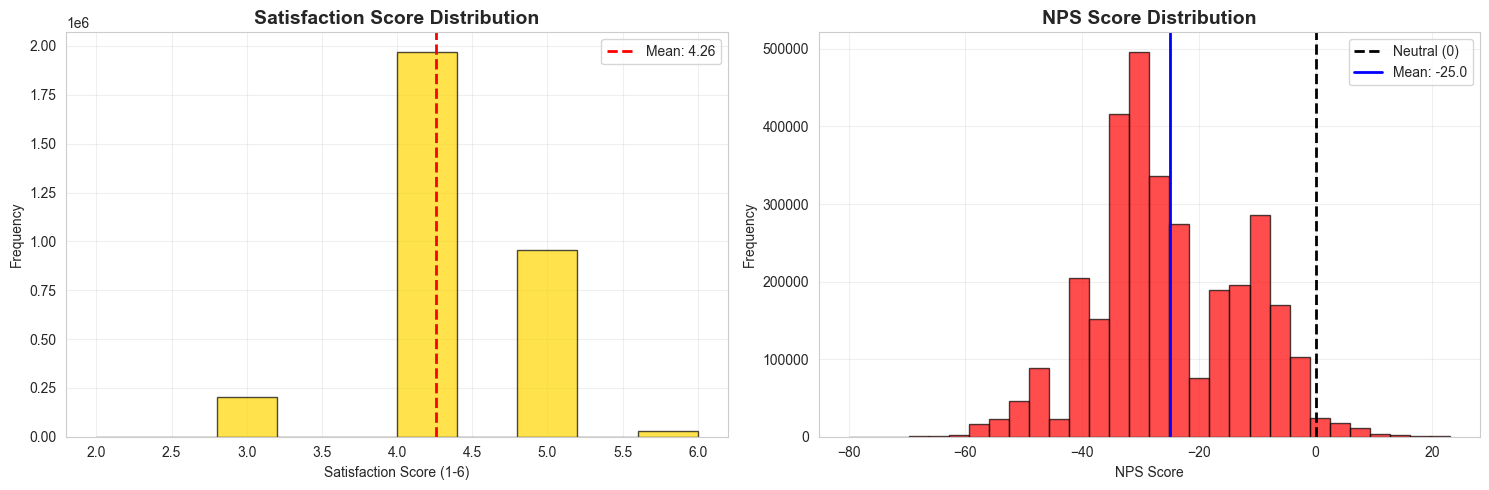

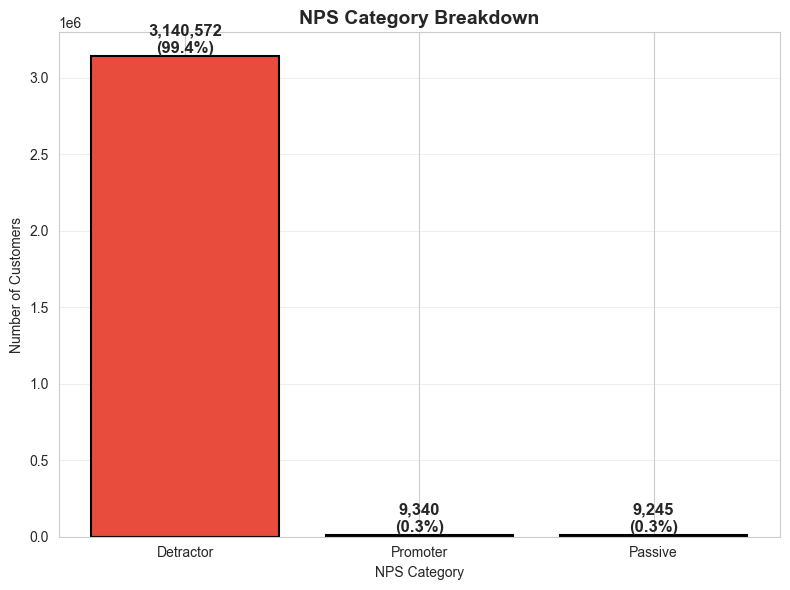

In [20]:
# ============================================
# CATEGORY 6: CUSTOMER SATISFACTION & NPS
# ============================================
print("\n" + "=" * 60)
print("CATEGORY 6: CUSTOMER SATISFACTION & NPS")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Satisfaction Score Distribution
merged_dataDF['satisfaction_score'].hist(bins=10, ax=axes[0], edgecolor='black', alpha=0.7, color='gold')
axes[0].axvline(merged_dataDF['satisfaction_score'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['satisfaction_score'].mean():.2f}")
axes[0].set_title('Satisfaction Score Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Satisfaction Score (1-6)')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# NPS Score Distribution
merged_dataDF['nps_score'].hist(bins=30, ax=axes[1], edgecolor='black', alpha=0.7, color='red')
axes[1].axvline(0, color='black', linestyle='--', linewidth=2, label='Neutral (0)')
axes[1].axvline(merged_dataDF['nps_score'].mean(), color='blue', linestyle='-', linewidth=2,
                label=f"Mean: {merged_dataDF['nps_score'].mean():.1f}")
axes[1].set_title('NPS Score Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('NPS Score')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================
# NPS CATEGORY BREAKDOWN - BAR CHART (CORRECT COLORS)
# ============================================

# Create NPS categories
def nps_category(score):
    if score >= 9:
        return 'Promoter'
    elif score >= 7:
        return 'Passive'
    else:
        return 'Detractor'

merged_dataDF['nps_category'] = merged_dataDF['nps_score'].apply(nps_category)
nps_counts = merged_dataDF['nps_category'].value_counts()

# Correct colors: Green = Good, Yellow = Neutral, Red = Bad
colors = {'Promoter': '#2ecc71', 'Passive': '#f39c12', 'Detractor': '#e74c3c'}
bar_colors = [colors[cat] for cat in nps_counts.index]

# Bar chart
plt.figure(figsize=(8, 6))
bars = plt.bar(nps_counts.index, nps_counts.values, color=bar_colors, edgecolor='black', linewidth=1.5)

# Add value labels on top of bars
for bar, count in zip(bars, nps_counts.values):
    pct = (count / len(merged_dataDF)) * 100
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000, 
             f'{count:,}\n({pct:.1f}%)', 
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title('NPS Category Breakdown', fontsize=14, fontweight='bold')
plt.xlabel('NPS Category')
plt.ylabel('Number of Customers')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

**CATEGORY 6: CUSTOMER SATISFACTION & NPS Observations:**
- Overall Satisfaction: Customers report relatively high overall satisfaction, with an average satisfaction score of 4.26 out of 6. Most customers rate their experience 4 or higher, while very few provide ratings below 2, suggesting that customers are generally satisfied with the bank's products and services.
- Transaction Satisfaction: Transaction satisfaction is consistently high, with a median score of 1.0 out of 1.0, indicating that most customers are satisfied with their transaction experiences. This observation is consistent with the low number of failed transactions observed earlier.
- Customer Advocacy: Despite relatively high satisfaction scores and a favourable average app rating (4.16 out of 5), the average Net Promoter Score (NPS) is -25, indicating that there are substantially more detractors than promoters. This suggests that positive customer experiences do not necessarily translate into a willingness to recommend the bank to others.
- Business Insight: The contrast between relatively high satisfaction and a negative NPS suggests opportunities to improve customer advocacy and loyalty beyond maintaining service quality. Further analysis could investigate whether factors such as customer support experiences, pricing, or customer engagement contribute to lower recommendation rates.


CATEGORY 7: SUPPORT & SERVICE


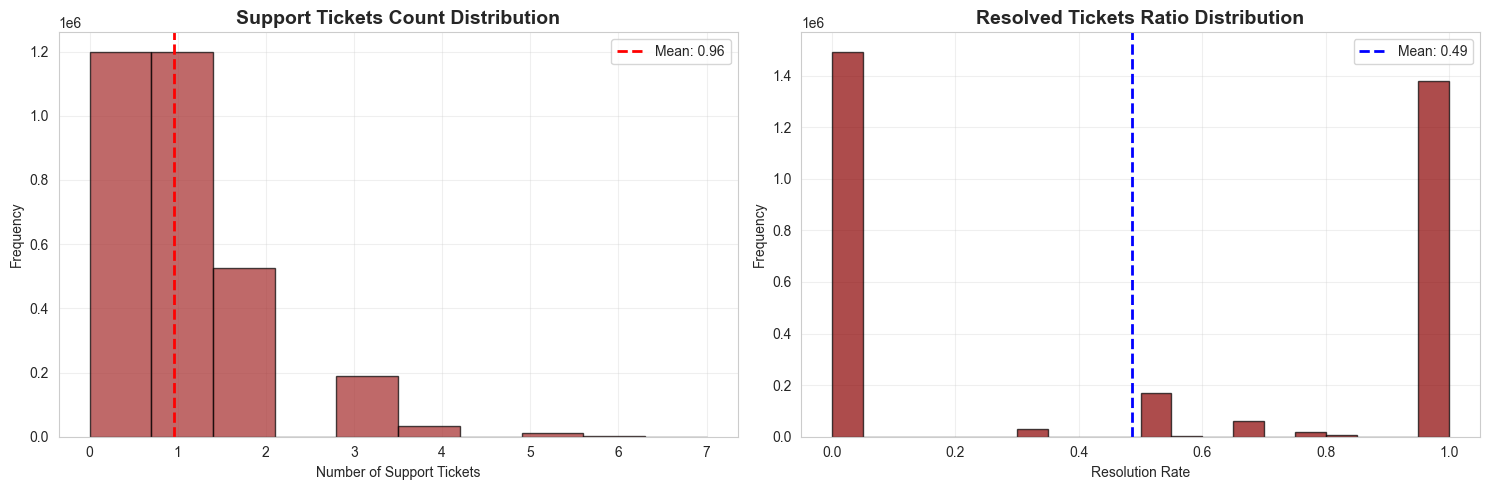

In [21]:
# ============================================
# CATEGORY 7: SUPPORT & SERVICE
# ============================================
print("\n" + "=" * 60)
print("CATEGORY 7: SUPPORT & SERVICE")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Support Tickets Count
merged_dataDF['support_tickets_count'].hist(bins=10, ax=axes[0], edgecolor='black', alpha=0.7, color='brown')
axes[0].axvline(merged_dataDF['support_tickets_count'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['support_tickets_count'].mean():.2f}")
axes[0].set_title('Support Tickets Count Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Support Tickets')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Resolved Tickets Ratio
merged_dataDF['resolved_tickets_ratio'].hist(bins=20, ax=axes[1], edgecolor='black', alpha=0.7, color='darkred')
axes[1].axvline(merged_dataDF['resolved_tickets_ratio'].mean(), color='blue', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['resolved_tickets_ratio'].mean():.2f}")
axes[1].set_title('Resolved Tickets Ratio Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Resolution Rate')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Category 7: SUPPORT & SERVICE Observation:**
- Support Volume: Customers open an average of 1 support ticket with a range of 0 to 7 tickets. This indicates the majority of customers require minimal support, suggesting generally smooth banking operations.
- Resolution Rate: The resolved tickets ratio shows a bimodal distribution with distinct peaks at 0.0 and 1.0, rather than a normal distribution around the mean of 0.49. This reveals a polarized service quality pattern where some customers receive 100% resolution while others receive 0% resolution, with very few customers falling in between. This bimodal pattern indicates a service inconsistency issue rather than a simple "50% average" problem.
- Service Polarization: The two distinct groups (fully resolved vs. completely unresolved) suggest systemic support inconsistencies. Customers with 0% resolution are likely frustrated, potentially driving the negative NPS.

- Improvement Opportunity: Address the root cause of the bimodal distribution rather than simply improving the average. Investigate differences in support channels, issue types, agent performance, or customer segments to identify and close service gaps.


CATEGORY 8: CUSTOMER VALUE & RISK


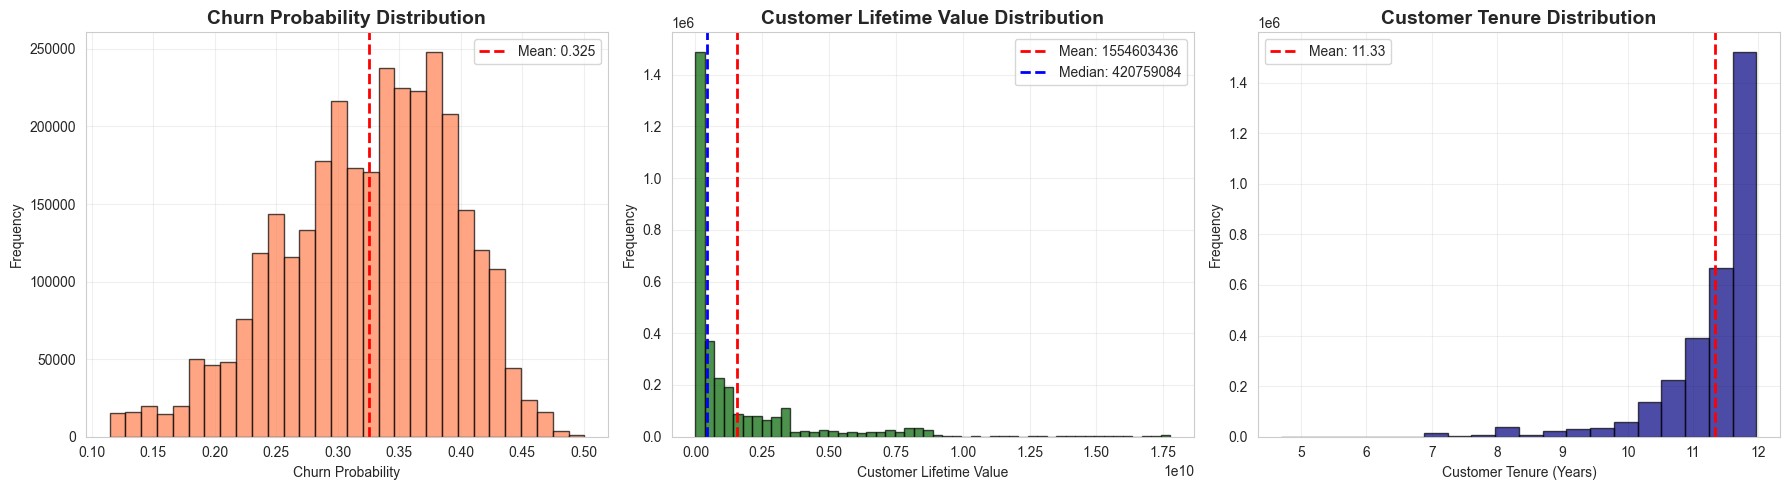

In [22]:
# ============================================
# CATEGORY 8: CUSTOMER VALUE & RISK
# ============================================
print("\n" + "=" * 60)
print("CATEGORY 8: CUSTOMER VALUE & RISK")
print("=" * 60)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Churn Probability
merged_dataDF['churn_probability'].hist(bins=30, ax=axes[0], edgecolor='black', alpha=0.7, color='coral')
axes[0].axvline(merged_dataDF['churn_probability'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['churn_probability'].mean():.3f}")
axes[0].set_title('Churn Probability Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Churn Probability')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Customer Lifetime Value
merged_dataDF['customer_lifetime_value'].hist(bins=50, ax=axes[1], edgecolor='black', alpha=0.7, color='darkgreen')
axes[1].axvline(merged_dataDF['customer_lifetime_value'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['customer_lifetime_value'].mean():.0f}")
axes[1].axvline(merged_dataDF['customer_lifetime_value'].median(), color='blue', linestyle='--', linewidth=2,
                label=f"Median: {merged_dataDF['customer_lifetime_value'].median():.0f}")
axes[1].set_title('Customer Lifetime Value Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Customer Lifetime Value')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Customer Tenure
merged_dataDF['customer_tenure'].hist(bins=20, ax=axes[2], edgecolor='black', alpha=0.7, color='navy')
axes[2].axvline(merged_dataDF['customer_tenure'].mean(), color='red', linestyle='--', linewidth=2,
                label=f"Mean: {merged_dataDF['customer_tenure'].mean():.2f}")
axes[2].set_title('Customer Tenure Distribution', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Customer Tenure (Years)')
axes[2].set_ylabel('Frequency')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

CATEGORY 8: CUSTOMER VALUE & RISK Observations:
- Churn Risk: The average churn probability is 33%, with values ranging from 11% to 50%, indicating varying levels of customer attrition risk across the customer base. This suggests that while many customers exhibit relatively low churn risk, others may benefit from targeted retention strategies.
- Customer Lifetime Value (CLV): Customer Lifetime Value is highly right-skewed, with a mean of 1.55 billion COP compared to a median of 0.42 billion COP. This indicates that a relatively small group of high-value customers contributes disproportionately to overall customer value, making customer segmentation particularly important.
- Customer Tenure: Customer tenure ranges from approximately 4.7 to 12 years, with relatively limited variation across customers. Compared with typical banking datasets, this narrow range may reflect synthetic data generation, preprocessing decisions, or sampling constraints rather than the full diversity of customer tenure typically observed in practice.
- Business Insight: The combination of highly skewed CLV and varying churn probabilities suggests that retention efforts may be most effective when prioritising high-value customers who also exhibit elevated churn risk.


CATEGORY 9: CATEGORICAL COLUMNS DISTRIBUTION

Categorical columns found: 11


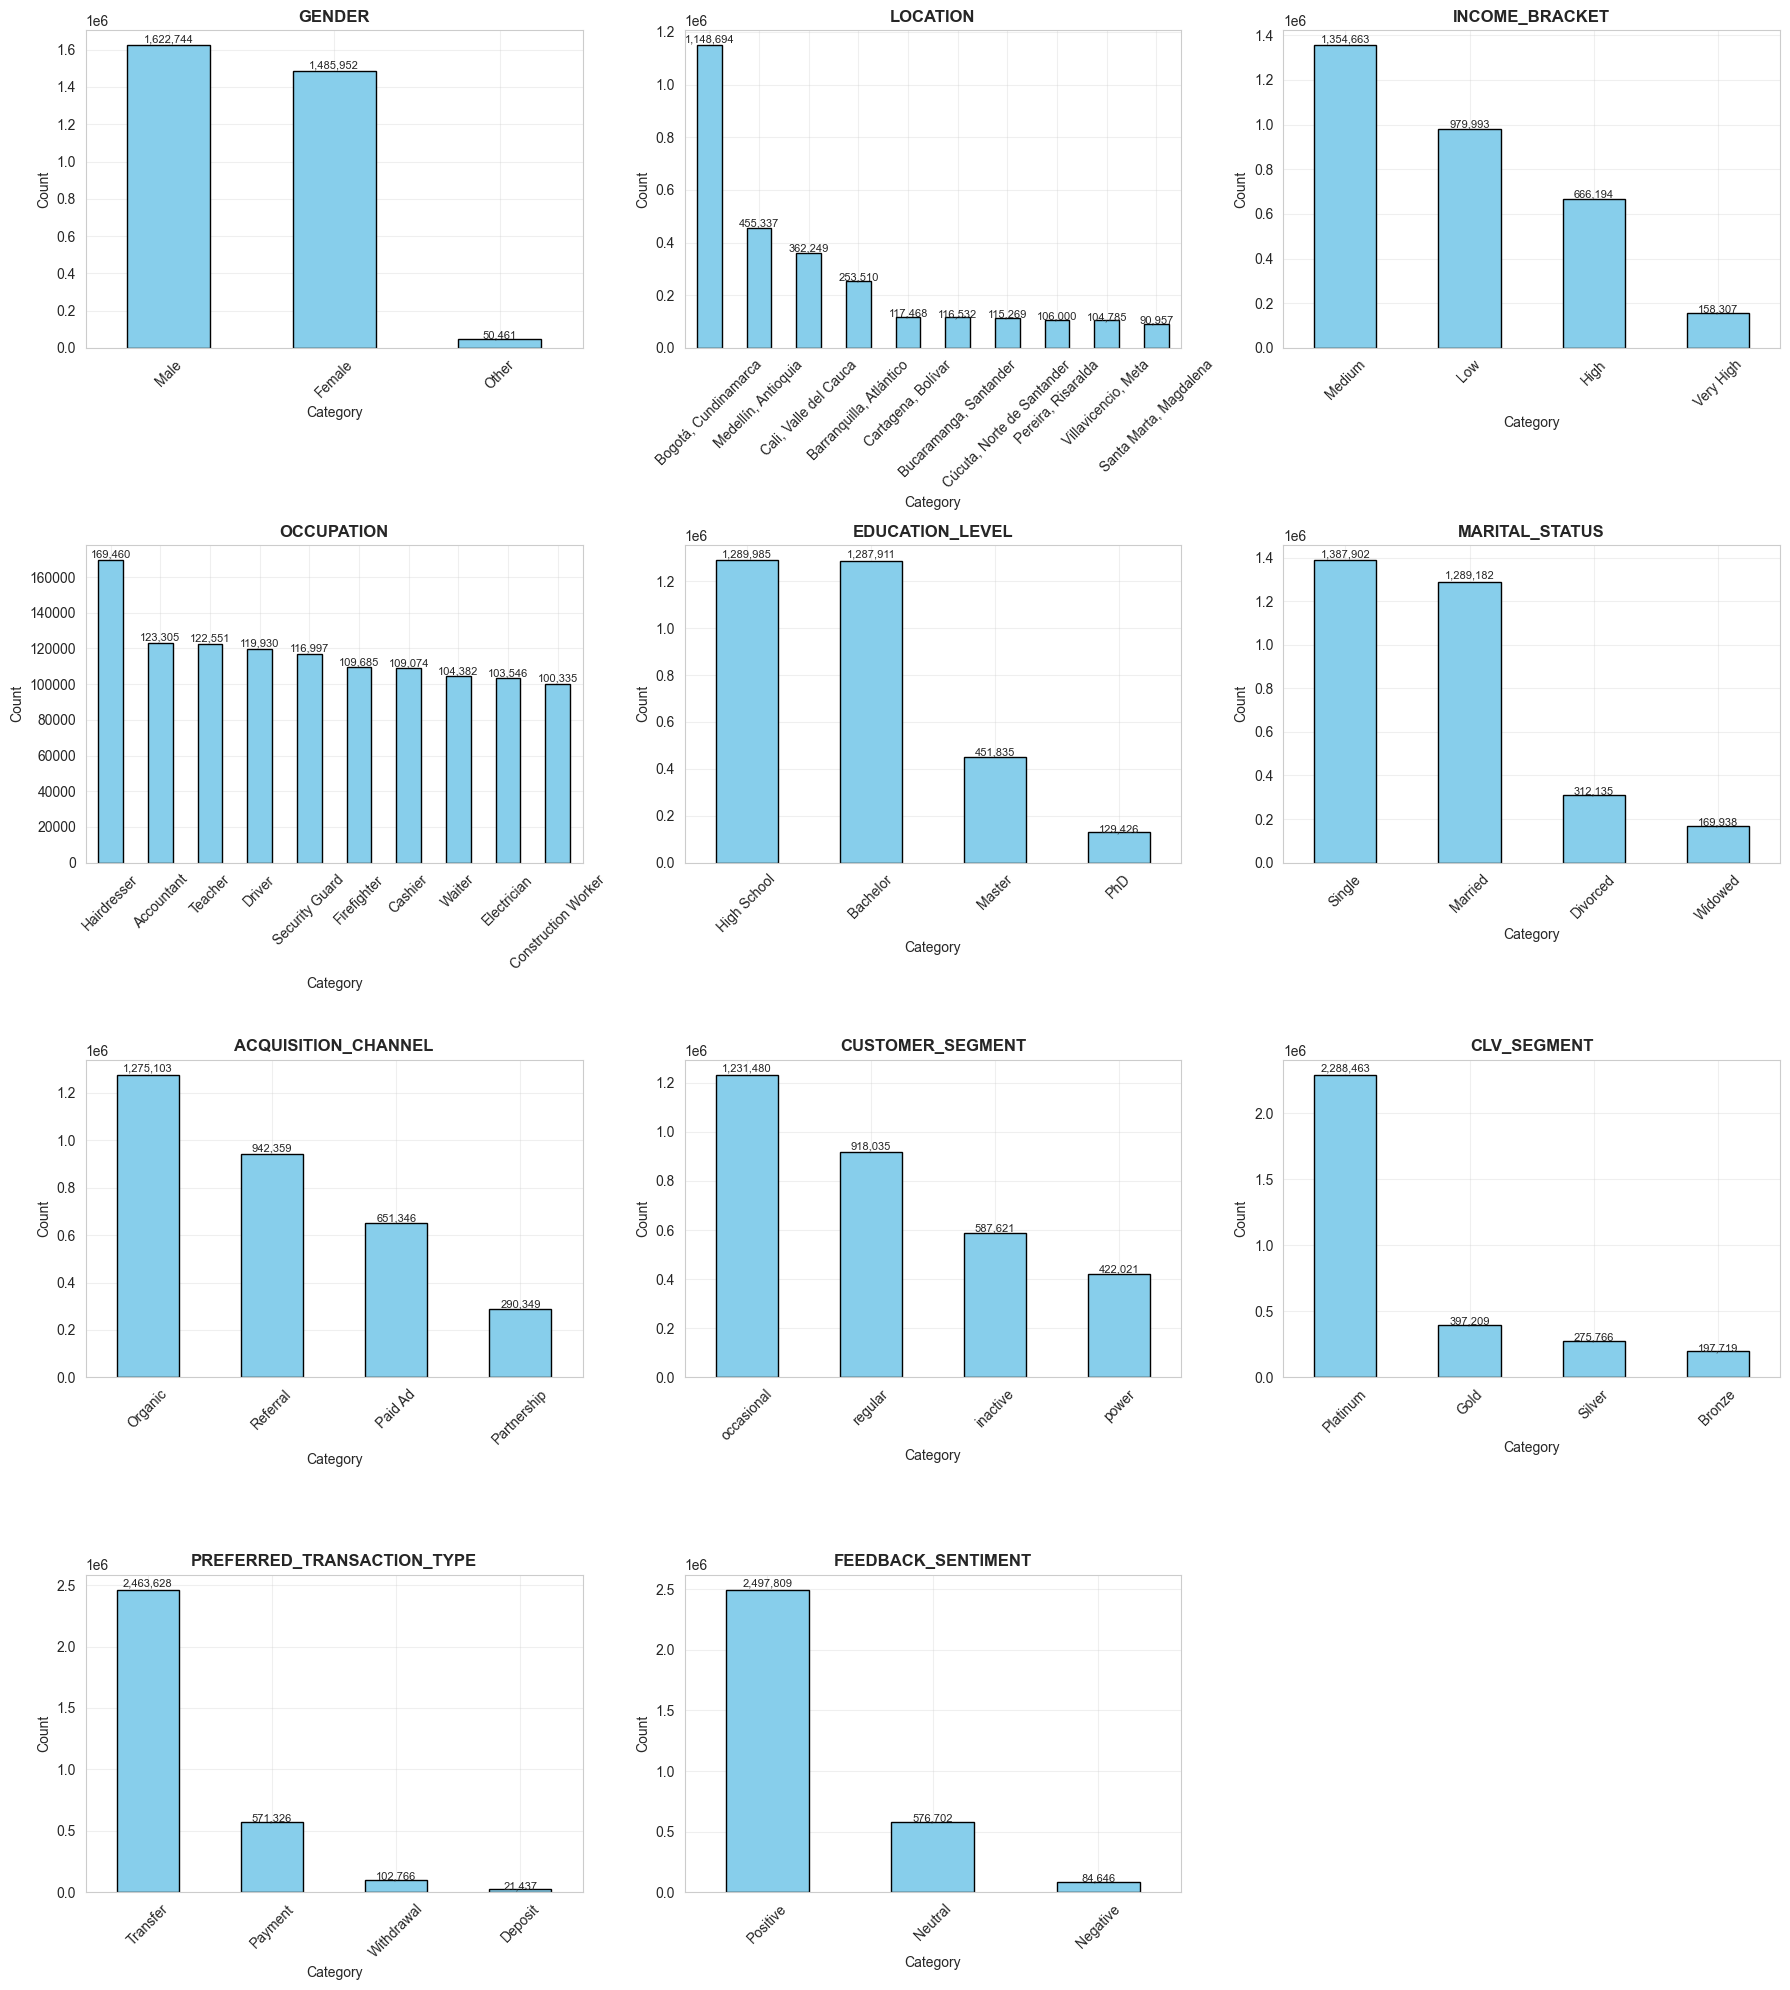


CATEGORICAL COLUMN VALUE COUNTS

🔹 GENDER:
----------------------------------------
   1. Male: 1,622,744 (51.4%)
   2. Female: 1,485,952 (47.0%)
   3. Other: 50,461 (1.6%)
   Total unique values: 3

🔹 LOCATION:
----------------------------------------
   1. Bogotá, Cundinamarca: 1,148,694 (36.4%)
   2. Medellín, Antioquia: 455,337 (14.4%)
   3. Cali, Valle del Cauca: 362,249 (11.5%)
   4. Barranquilla, Atlántico: 253,510 (8.0%)
   5. Cartagena, Bolívar: 117,468 (3.7%)
   ... and 13 more categories
   Total unique values: 18

🔹 INCOME_BRACKET:
----------------------------------------
   1. Medium: 1,354,663 (42.9%)
   2. Low: 979,993 (31.0%)
   3. High: 666,194 (21.1%)
   4. Very High: 158,307 (5.0%)
   Total unique values: 4

🔹 OCCUPATION:
----------------------------------------
   1. Hairdresser: 169,460 (5.4%)
   2. Accountant: 123,305 (3.9%)
   3. Teacher: 122,551 (3.9%)
   4. Driver: 119,930 (3.8%)
   5. Security Guard: 116,997 (3.7%)
   ... and 30 more categories
   Total uniqu

In [23]:
# ============================================
# CATEGORY 9: CATEGORICAL COLUMNS DISTRIBUTION
# ============================================
print("\n" + "=" * 60)
print("CATEGORY 9: CATEGORICAL COLUMNS DISTRIBUTION")
print("=" * 60)

# Define categorical columns
categorical_cols = ['gender', 'location', 'income_bracket', 'occupation', 'education_level',
                    'marital_status', 'acquisition_channel', 'customer_segment', 'clv_segment',
                    'preferred_transaction_type', 'feedback_sentiment']

# Filter to only columns that exist in the dataset
categorical_cols = [col for col in categorical_cols if col in merged_dataDF.columns]

print(f"\nCategorical columns found: {len(categorical_cols)}")

# Create subplots (3 columns, dynamic rows)
n_cols = len(categorical_cols)
n_rows = (n_cols // 3) + (1 if n_cols % 3 != 0 else 0)

fig, axes = plt.subplots(n_rows, 3, figsize=(18, n_rows * 5))
axes = axes.flatten()

for idx, col in enumerate(categorical_cols):
    # Get value counts and top 10 categories
    value_counts = merged_dataDF[col].value_counts().head(10)
    
    # Create bar plot
    value_counts.plot(kind='bar', ax=axes[idx], color='skyblue', edgecolor='black')
    axes[idx].set_title(f'{col.upper()}', fontweight='bold', fontsize=12)
    axes[idx].set_xlabel('Category')
    axes[idx].set_ylabel('Count')
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].grid(True, alpha=0.3)
    
    # Add value labels on top of bars
    for i, v in enumerate(value_counts):
        axes[idx].text(i, v + (v * 0.01), f'{v:,}', ha='center', fontsize=8)

# Hide empty subplots
for idx in range(len(categorical_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

# ============================================
# PRINT VALUE COUNTS FOR EACH CATEGORICAL COLUMN
# ============================================
print("\n" + "=" * 60)
print("CATEGORICAL COLUMN VALUE COUNTS")
print("=" * 60)

for col in categorical_cols:
    print(f"\n🔹 {col.upper()}:")
    print("-" * 40)
    value_counts = merged_dataDF[col].value_counts()
    
    # Print top 5 categories
    for i, (cat, count) in enumerate(value_counts.head(5).items(), 1):
        pct = (count / len(merged_dataDF)) * 100
        print(f"   {i}. {cat}: {count:,} ({pct:.1f}%)")
    
    # Print total unique values
    if len(value_counts) > 5:
        print(f"   ... and {len(value_counts)-5} more categories")
    print(f"   Total unique values: {len(value_counts)}")

**CATEGORY 9: CATEGORICAL COLUMNS DISTRIBUTION Observations:**
- Customer Demographics: Demographic variables such as gender, location, occupation, education level, and marital status contain multiple customer groups with varying frequencies. These variables provide useful segmentation features for analysing differences in customer behaviour across demographic profiles.
- Customer Segmentation: The dataset includes predefined customer segments and CLV segments, indicating that customers have already been categorised based on business-defined characteristics. These variables may be valuable for comparing behavioural and financial differences across customer groups.
- Acquisition Channels: Customers are acquired through multiple channels, including online platforms, physical branches, and referrals. This diversity enables comparisons of customer behaviour and performance across different acquisition sources.
- Feedback Sentiment: Customer feedback includes positive, neutral, and negative sentiment categories. These variables can be analysed alongside satisfaction scores and NPS to better understand the relationship between customer experience and customer advocacy.
- Transaction Preferences: Customers exhibit different preferred transaction types, reflecting diverse transaction behaviours. These preferences may provide useful information for customer segmentation, product recommendations, and behavioural analysis.